In [14]:
import random
from zipfile import ZipFile
import cv2
import numpy as np
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

random.seed(42)

# ГЕНЕРАЦИЯ НАБОРА ДАННЫХ

In [15]:
IMAGE_SIZE = 32
SYMBOL_SIZE = 45
archive = ZipFile('data.zip')

def get_class_files():
    class_files = {}
    for path in archive.namelist():
        parts = path.split('/')
        if len(parts) == 2 and parts[1].lower().endswith('.jpg'):
            label = parts[0]
            class_files.setdefault(label, []).append(path)
    return {label: class_files[label] for label in sorted(class_files)}


def read_image(path):
    data = np.frombuffer(archive.read(path), dtype=np.uint8)
    return cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)


class_files = get_class_files()
name_folders = list(class_files.keys())
print('классов:', len(name_folders))
print(name_folders)

классов: 21
['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', 'times', 'w', 'y']


In [16]:
def load_images(class_files, size=IMAGE_SIZE):
    X = []
    y = []
    file_names = []
    for label, files in class_files.items():
        for path in files:
            img = read_image(path)
            if img is None:
                continue
            img = cv2.resize(img, (size,size))
            img = cv2.bitwise_not(img)
            X.append(img.flatten())
            y.append(label)
            file_names.append(path)
    return np.asarray(X, np.uint8), np.asarray(y), np.asarray(file_names)


X, y, file_names = load_images(class_files)
print('изображений:', X.shape, y.shape)

изображений: (225291, 1024) (225291,)


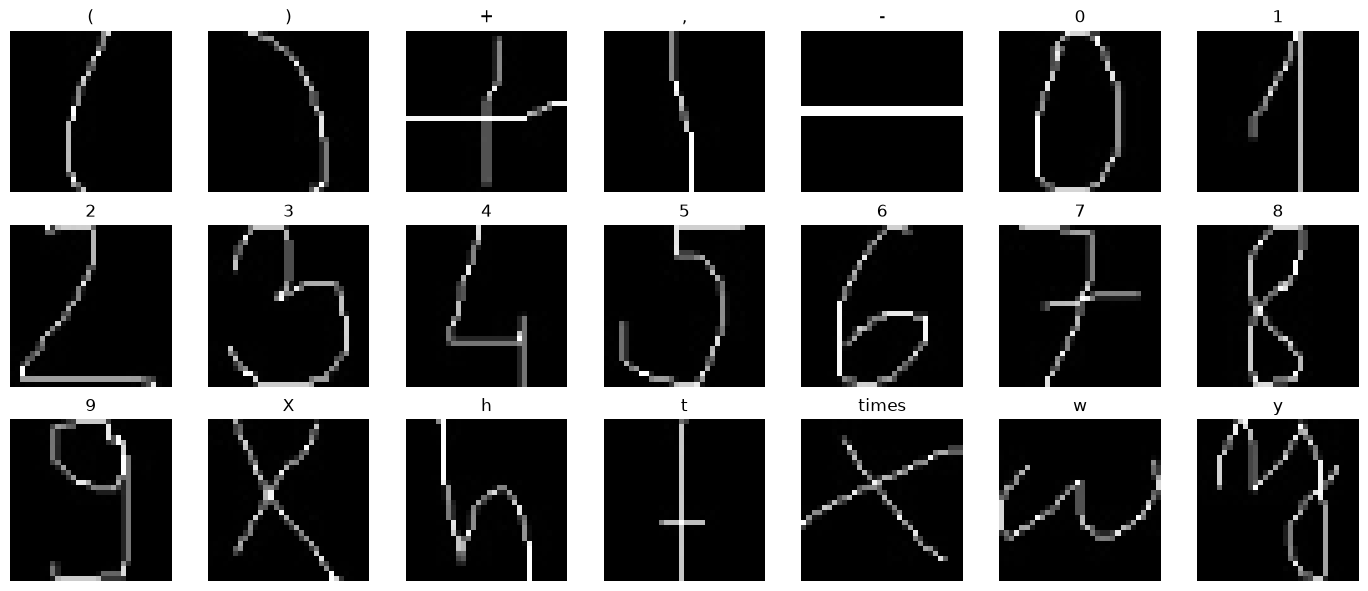

In [17]:
plt.figure(figsize=(14, 6))
for i, label in enumerate(name_folders):
    idx = np.where(y == label)[0][0]
    plt.subplot(3, 7, i+1)
    plt.imshow(X[idx].reshape(IMAGE_SIZE, IMAGE_SIZE), cmap='gray')
    plt.title(label)
    plt.axis('off')
plt.tight_layout()
plt.show()

# КЛАССИФИКАЦИЯ

In [18]:
X_train, X_test, y_train, y_test, files_train, files_test = train_test_split(
    X, y, file_names, test_size=0.2, random_state=42, stratify=y
)
del X
X_train = X_train.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
print('train:', X_train.shape, 'test:', X_test.shape)

test_class_files = {label: files_test[y_test == label].tolist() for label in name_folders}

train: (180232, 1024) test: (45059, 1024)


k = 1 accuracy: 0.9917
k = 3 accuracy: 0.9387
k = 5 accuracy: 0.8343
k = 7 accuracy: 0.805
k = 9 accuracy: 0.779
k = 11 accuracy: 0.7553
лучшее k: 1


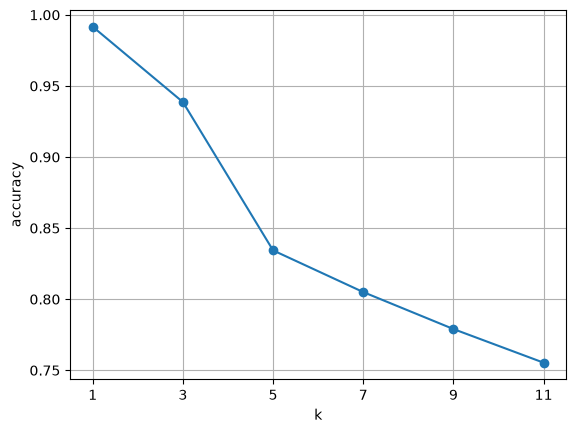

In [19]:
X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train, y_train, test_size=3000, random_state=42, stratify=y_train
)
k_values = [1, 3, 5, 7, 9, 11]
accuracies = []

for k in k_values:
    classifier = KNeighborsClassifier(n_neighbors=k, algorithm='brute', n_jobs=-1)
    classifier.fit(X_fit, y_fit)
    y_pred = classifier.predict(X_valid)
    acc = accuracy_score(y_valid, y_pred)
    accuracies.append(acc)
    print('k =', k, 'accuracy:', round(acc, 4))

best_k = k_values[int(np.argmax(accuracies))]
print('лучшее k:', best_k)
del classifier, X_fit, X_valid, y_fit, y_valid

plt.plot(k_values, accuracies, 'o-')
plt.xlabel('k')
plt.ylabel('accuracy')
plt.xticks(k_values)
plt.grid()
plt.show()

In [20]:
best_classifier = KNeighborsClassifier(n_neighbors=best_k, algorithm='brute', n_jobs=-1)
best_classifier.fit(X_train, y_train)
y_pred_test = best_classifier.predict(X_test)
test_acc = accuracy_score(y_test, y_pred_test)
print('accuracy, test:', round(test_acc, 4))
print(classification_report(y_test, y_pred_test, zero_division=0))

accuracy, test: 0.9913
              precision    recall  f1-score   support

           (       0.98      1.00      0.99      2859
           )       0.98      1.00      0.99      2871
           +       1.00      0.99      0.99      5022
           ,       0.90      0.93      0.91       381
           -       0.99      1.00      1.00      6799
           0       1.00      1.00      1.00      1383
           1       0.98      1.00      0.99      5304
           2       0.99      1.00      0.99      5228
           3       0.99      0.99      0.99      2182
           4       1.00      0.99      0.99      1479
           5       1.00      0.99      0.99       709
           6       1.00      0.97      0.99       624
           7       0.99      0.99      0.99       582
           8       1.00      0.96      0.98       614
           9       1.00      0.44      0.61       126
           X       1.00      0.99      1.00      5319
           h       1.00      1.00      1.00       293
    

# РАСПОЗНАВАНИЕ

In [21]:
SYMBOL_SPACING = 15
WORD_SPACING = 45

def load_random_symbol(label):
    path = random.choice(test_class_files[label])
    return read_image(path)


def generate_sequence(num_words=1, min_len=2, max_len=4, labels=None):
    if labels is None:
        labels = name_folders
    words = []
    images = []
    gaps = []
    for w in range(num_words):
        length = random.randint(min_len, max_len)
        word = [random.choice(labels) for i in range(length)]
        words.append(word)
        for i, label in enumerate(word):
            images.append(load_random_symbol(label))
            if i < length-1:
                gaps.append(SYMBOL_SPACING)
        if w < num_words-1:
            gaps.append(WORD_SPACING)
    text = ' '.join(''.join(label if label != 'times' else '*' for label in word)
                    for word in words)
    return text, images, gaps


def compose_sequence(images, gaps, margin=20):
    h = max(img.shape[0] for img in images)
    width = margin*2 + sum(img.shape[1] for img in images) + sum(gaps)
    canvas = np.full((h+2*margin, width), 255, np.uint8)
    x = margin
    for i, img in enumerate(images):
        y = margin + (h-img.shape[0])//2
        canvas[y:y+img.shape[0], x:x+img.shape[1]] = img
        x += img.shape[1]
        if i < len(gaps):
            x += gaps[i]
    return canvas

32 -> 2 символов
t+*8 -> 4 символов
w(t1 -> 4 символов
*3( -> 3 символов
15 ,66 -> 5 символов


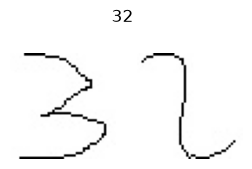

In [22]:
generated = [generate_sequence(num_words=random.randint(1,2)) for i in range(5)]
for text, images, gaps in generated:
    print(text, '->', len(images), 'символов')

first_text, first_images, first_gaps = generated[0]
plt.figure(figsize=(len(first_images)*1.5, 2))
for i, img in enumerate(first_images):
    plt.subplot(1, len(first_images), i+1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
plt.suptitle(first_text)
plt.show()

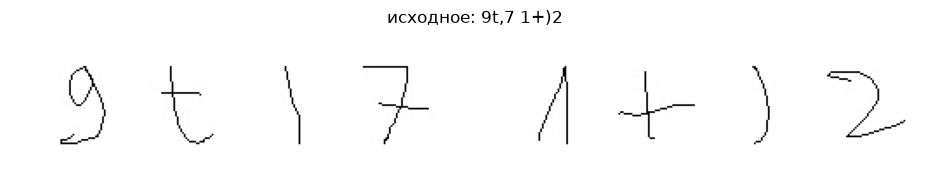

In [23]:
test_text, test_images, test_gaps = generate_sequence(num_words=2, min_len=2, max_len=4)
test_image = compose_sequence(test_images, test_gaps)
plt.figure(figsize=(12, 3))
plt.imshow(test_image, cmap='gray')
plt.title('исходное: ' + test_text)
plt.axis('off')
plt.show()

In [24]:
def segment_symbols(image):
    if len(image.shape) == 3:
        img_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        img_gray = image.copy()
    source_gray = img_gray.copy()
    kernel = np.ones((3,3), np.uint8)
    img_gray = cv2.erode(img_gray, kernel, iterations=1)
    img_gray = cv2.bitwise_not(img_gray)
    base_size = img_gray.shape[0]+6, img_gray.shape[1]+6
    base = np.zeros(base_size, np.uint8)
    base[3:img_gray.shape[0]+3, 3:img_gray.shape[1]+3] = img_gray
    img_rgb = cv2.cvtColor(base, cv2.COLOR_GRAY2RGB)
    ret, thresh = cv2.threshold(img_rgb, 127, 255, 0)
    contours,h = cv2.findContours(thresh[:,:,0], cv2.RETR_EXTERNAL, 2)
    crops = []
    for cnt in contours:
        x,y,w,h = cv2.boundingRect(cnt)
        if w*h > 50:
            cv2.rectangle(img_rgb, (x,y), (x+w,y+h), (0,0,255), 2)
            crops.append([x,y,w,h])
    crops = sorted(crops, key=lambda b: b[0])
    data_img = []
    for x,y,w,h in crops:
        x = max(0, min(x-3+w//2-SYMBOL_SIZE//2, source_gray.shape[1]-SYMBOL_SIZE))
        y = max(0, min(y-3+h//2-SYMBOL_SIZE//2, source_gray.shape[0]-SYMBOL_SIZE))
        img = source_gray[y:y+SYMBOL_SIZE, x:x+SYMBOL_SIZE]
        data_img.append((x,cv2.bitwise_not(img)))
    return img_rgb, crops, data_img

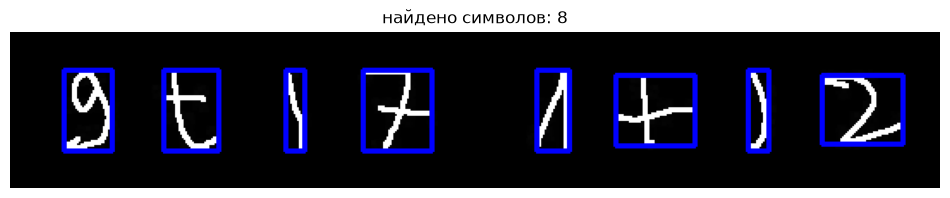

координаты: [[31, 22, 28, 47], [89, 22, 32, 47], [160, 22, 11, 47], [205, 22, 40, 47], [306, 22, 19, 47], [352, 25, 46, 41], [429, 22, 12, 47], [472, 25, 47, 40]]


In [25]:
img_rgb, crops, data_img = segment_symbols(test_image)
plt.figure(figsize=(12, 3))
plt.imshow(img_rgb)
plt.title('найдено символов: ' + str(len(crops)))
plt.axis('off')
plt.show()
print('координаты:', crops)

In [26]:
def classify_symbols(data_img, model):
    predict_labels = []
    for x, img in data_img:
        img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE))
        img = np.asarray(img, dtype=np.float32) / 255
        label = model.predict(img.reshape(1,-1))[0]
        predict_labels.append(label)
    return predict_labels


predict_labels = classify_symbols(data_img, best_classifier)
centers = [x+w//2 for x,y,w,h in crops]
gaps = [centers[i+1] - centers[i] for i in range(len(centers)-1)]
SPACE_GAP = SYMBOL_SIZE + (SYMBOL_SPACING+WORD_SPACING)//2
s_res = ''
for i, label in enumerate(predict_labels):
    s_res += label if label != 'times' else '*'
    if i < len(gaps) and gaps[i] > SPACE_GAP:
        s_res += ' '
print('исходное: ', test_text)
print('результат:', s_res)

исходное:  9t,7 1+)2
результат: 5t,7 1+)2
